--- Step 1: Ingesting & Downcasting Datasets ---

--- Step 2: Executing Strict 4-Way Temporal Data Split ---
--- Step 3: Feature Engineering with Strict 28-Day Lag Constraints ---
Train split range:       2013-12-19 to 2015-12-06 (2189182 rows)
Validation split range:  2015-12-07 to 2016-01-03 (85372 rows)
Calibration split range: 2016-01-04 to 2016-02-28 (170744 rows)
Test split range:        2016-02-29 to 2016-03-27 (85372 rows)

--- Step 4: Generating Fixed-Origin Baselines & Training LightGBM ---

          UNSEEN TEST SET MODEL EVALUATION BENCHMARK REPORT             
                         Model Pipeline    MAE   RMSE  WAPE (%)
      Naive Benchmark (Constant Scalar) 1.6320 3.5572    111.24
Seasonal Naive (Repeated 7-Day Pattern) 1.2753 2.8183     86.93
     LightGBM (Proposed Model Pipeline) 1.1369 2.2499     77.50

--- Step 5: Multi-Origin Calibration Window Error & Bias Tracking ---
Complete 7-day lead-time calibration origins evaluated: 49 windows

   ESTIMATED LEAD-TIME IN

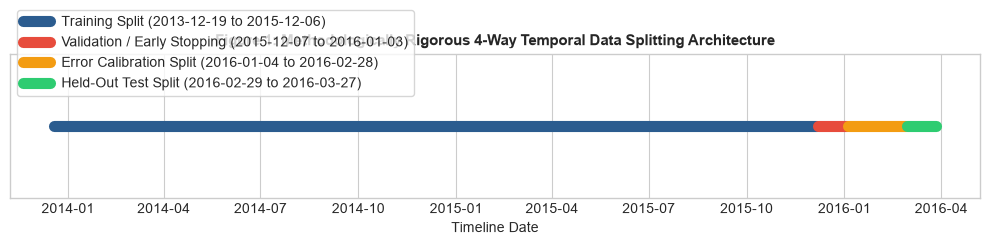

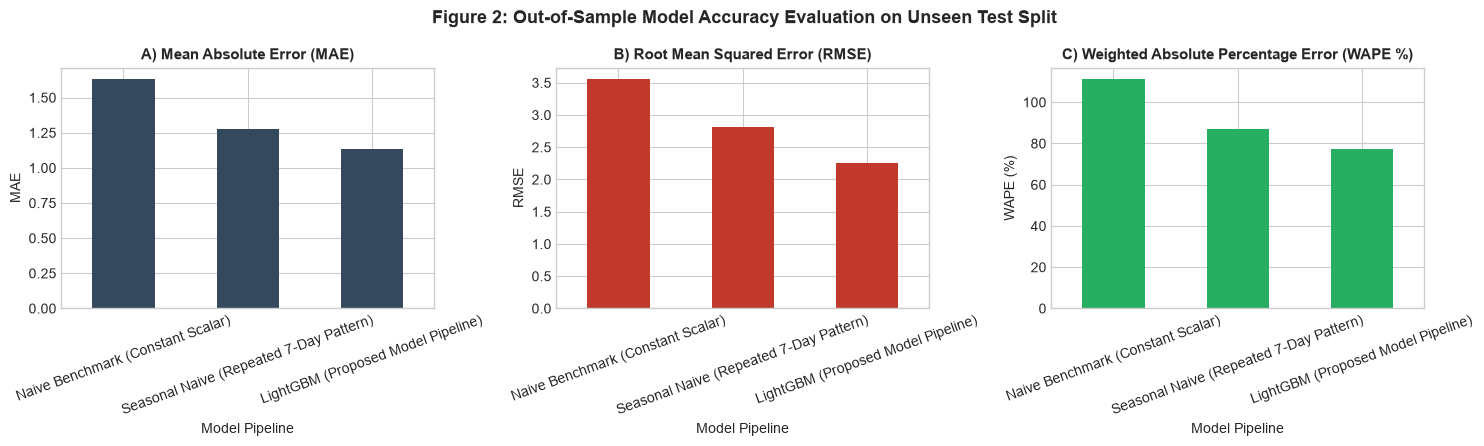

<Figure size 900x450 with 0 Axes>

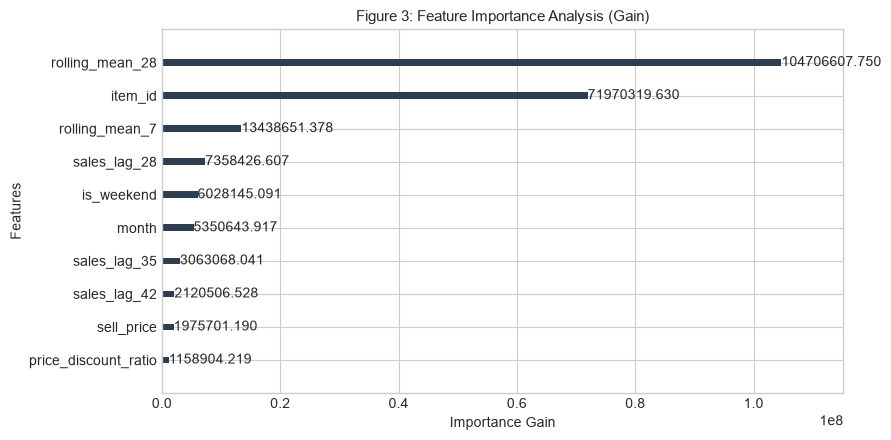

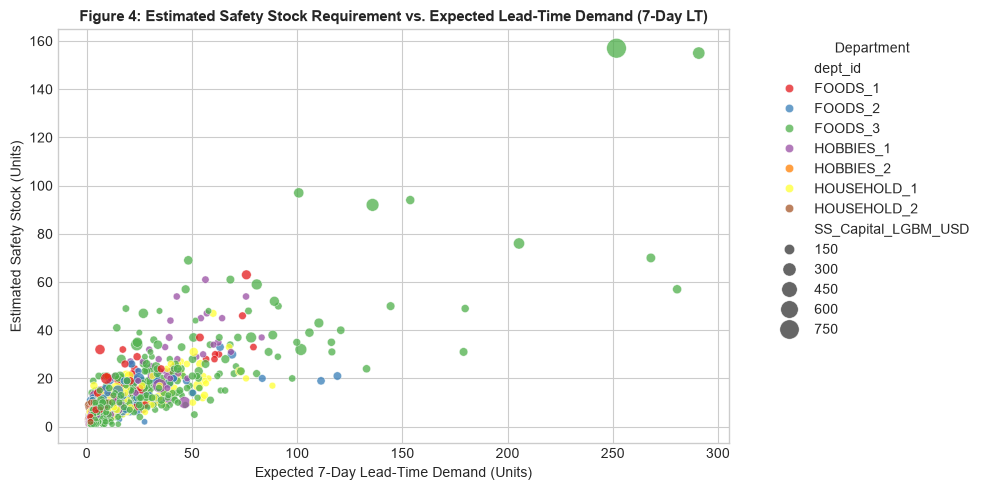

In [1]:
# ==============================================================================
# AI-BASED RETAIL DEMAND FORECASTING AND INVENTORY POLICY ANALYSIS
# Dataset: M5 Forecasting Benchmark (Walmart Sales Dataset)
# Academic Context: PhD Research Portfolio in Supply Chain Analytics / Operations Research
# Architecture: Leak-Free 4-Way Temporal Split -> Fixed-Origin Multi-Step Baselines 
#               -> Non-Negative LightGBM -> Calibration Error Distribution -> Inventory Policy
# ==============================================================================

# ------------------------------------------------------------------------------
# LIBRARIES & INITIAL CONFIGURATION
# ------------------------------------------------------------------------------
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

# Selective warning filtering for clean execution logs without suppressing critical errors
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

# Set publication-grade plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.labelsize'] = 10

# Global Dataset Directory
DATA_DIR = "m5_data/"

# ==============================================================================
# SECTION 1: DATA INGESTION & PRECISION-PRESERVING DOWNCASTING
# ==============================================================================
def reduce_mem_usage(df, verbose=False):
    """
    Optimizes RAM usage by downcasting integer types while strictly preserving 
    float32 numerical precision for prices, financial values, and engineered features.
    """
    start_mem = df.memory_usage().sum() / 1024**2    
    for col in df.columns:
        col_type = df[col].dtypes
        if str(col_type)[:3] == 'int':
            c_min, c_max = df[col].min(), df[col].max()
            if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                df[col] = df[col].astype(np.int8)
            elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                df[col] = df[col].astype(np.int16)
            elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                df[col] = df[col].astype(np.int32)
            elif c_min > np.iinfo(np.int64).min and c_max < np.iinfo(np.int64).max:
                df[col] = df[col].astype(np.int64)  
        elif str(col_type)[:5] == 'float':
            # Maintain float32 precision across all decimal variables
            df[col] = df[col].astype(np.float32)
            
    end_mem = df.memory_usage().sum() / 1024**2
    if verbose:
        print(f"Memory usage decreased to {end_mem:.2f} MB ({100 * (start_mem - end_mem) / start_mem:.1f}% reduction)")
    return df

print("--- Step 1: Ingesting & Downcasting Datasets ---")

calendar = pd.read_csv(os.path.join(DATA_DIR, 'calendar.csv'))
sell_prices = pd.read_csv(os.path.join(DATA_DIR, 'sell_prices.csv'))
sales = pd.read_csv(os.path.join(DATA_DIR, 'sales_train_validation.csv'))

calendar = reduce_mem_usage(calendar)
sell_prices = reduce_mem_usage(sell_prices)
sales = reduce_mem_usage(sales)

# Scope filtering: Store 'CA_1'
STORE_ID = 'CA_1'
sales_ca1 = sales[sales['store_id'] == STORE_ID].copy()

# Select day columns d_1001 to d_1885 (slice indices 1000 to 1884)
day_cols = [c for c in sales_ca1.columns if 'd_' in c]
keep_days = day_cols[1000:1885] 

# Reshape Wide to Long
id_vars = ['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id']
df = pd.melt(sales_ca1, id_vars=id_vars, value_vars=keep_days, var_name='d', value_name='sales')

# Merge Calendar & Price Data
cal_cols = ['d', 'date', 'wm_yr_wk', 'weekday', 'month', 'year', 'event_name_1']
df = pd.merge(df, calendar[cal_cols], on='d', how='left')
df = pd.merge(df, sell_prices, on=['store_id', 'item_id', 'wm_yr_wk'], how='left')

df['date'] = pd.to_datetime(df['date'])
df = reduce_mem_usage(df)

# ==============================================================================
# SECTION 2: RIGOROUS 4-WAY TEMPORAL SPLIT & IN-SAMPLE PRICE STATS
# ==============================================================================
print("\n--- Step 2: Executing Strict 4-Way Temporal Data Split ---")

# Define non-overlapping chronological boundaries
max_date          = df['date'].max()                             # End date (d_1885)
test_start_date   = max_date - pd.Timedelta(days=27)             # Test: Last 28 days (d_1858 to d_1885)
calib_start_date  = test_start_date - pd.Timedelta(days=56)      # Calibration: Prior 56 days (d_1802 to d_1857)
val_start_date    = calib_start_date - pd.Timedelta(days=28)     # Validation (Early Stopping): Prior 28 days (d_1774 to d_1801)
train_end_date    = val_start_date - pd.Timedelta(days=1)        # Train: Prior history up to d_1773

# Sort chronologically per SKU
df = df.sort_values(by=['item_id', 'date']).reset_index(drop=True)

# Compute Price Statistics STRICTLY on Training Split to avoid lookahead bias
train_split_mask = df['date'] <= train_end_date

train_prices = df[train_split_mask].groupby('item_id')['sell_price'].agg(
    train_price_mean='mean',
    train_price_max='max'
).reset_index()

# Global fallback price calculated STRICTLY on the training set
global_train_price_mean = df[train_split_mask]['sell_price'].mean()

df = df.merge(train_prices, on='item_id', how='left')

# ASSUMPTION: Future sell prices and event flags are assumed known prior to forecast horizon (planned promotional schedule)
# Fallback Imputation: Missing item prices are imputed via in-sample item training mean, then global training mean
df['sell_price'] = df['sell_price'].fillna(df['train_price_mean']).fillna(global_train_price_mean)
df['train_price_max'] = df['train_price_max'].fillna(df['sell_price'])
df['price_discount_ratio'] = (1 - (df['sell_price'] / df['train_price_max'])).fillna(0).astype(np.float32)

df.drop(columns=['train_price_mean', 'train_price_max'], inplace=True)

# ==============================================================================
# SECTION 3: LEAK-FREE FEATURE ENGINEERING & CATEGORICAL ALIGNMENT
# ==============================================================================
print("--- Step 3: Feature Engineering with Strict 28-Day Lag Constraints ---")

df['is_weekend'] = df['weekday'].isin(['Saturday', 'Sunday']).astype(np.int8)
df['has_event'] = df['event_name_1'].notnull().astype(np.int8)

# ASSUMPTION: Direct row-by-row multi-step forecasting framework using lag_28+ features
df['sales_lag_28'] = df.groupby('item_id')['sales'].shift(28).astype(np.float32)
df['sales_lag_35'] = df.groupby('item_id')['sales'].shift(35).astype(np.float32)
df['sales_lag_42'] = df.groupby('item_id')['sales'].shift(42).astype(np.float32)

# Rolling window statistics shifted by 28 days
df['rolling_mean_7']  = df.groupby('item_id')['sales'].transform(lambda x: x.shift(28).rolling(7).mean()).astype(np.float32)
df['rolling_std_7']   = df.groupby('item_id')['sales'].transform(lambda x: x.shift(28).rolling(7).std()).astype(np.float32)
df['rolling_mean_28'] = df.groupby('item_id')['sales'].transform(lambda x: x.shift(28).rolling(28).mean()).astype(np.float32)

# Drop missing values generated by initial lags
df_clean = df.dropna(subset=['sales_lag_42', 'rolling_mean_28']).reset_index(drop=True)
df_clean = reduce_mem_usage(df_clean)

# Split datasets across the 4 chronological partitions
train_df = df_clean[df_clean['date'] <= train_end_date].copy()
val_df   = df_clean[(df_clean['date'] >= val_start_date) & (df_clean['date'] < calib_start_date)].copy()
calib_df = df_clean[(df_clean['date'] >= calib_start_date) & (df_clean['date'] < test_start_date)].copy()
test_df  = df_clean[df_clean['date'] >= test_start_date].copy()

# Enforce unified global categorical encoding across all splits
cat_cols = ['item_id', 'dept_id', 'cat_id']
for col in cat_cols:
    global_categories = df_clean[col].astype(str).unique()
    train_df[col] = pd.Categorical(train_df[col].astype(str), categories=global_categories)
    val_df[col]   = pd.Categorical(val_df[col].astype(str), categories=global_categories)
    calib_df[col] = pd.Categorical(calib_df[col].astype(str), categories=global_categories)
    test_df[col]  = pd.Categorical(test_df[col].astype(str), categories=global_categories)

print(f"Train split range:       {train_df['date'].min().date()} to {train_df['date'].max().date()} ({train_df.shape[0]} rows)")
print(f"Validation split range:  {val_df['date'].min().date()} to {val_df['date'].max().date()} ({val_df.shape[0]} rows)")
print(f"Calibration split range: {calib_df['date'].min().date()} to {calib_df['date'].max().date()} ({calib_df.shape[0]} rows)")
print(f"Test split range:        {test_df['date'].min().date()} to {test_df['date'].max().date()} ({test_df.shape[0]} rows)")

# ==============================================================================
# SECTION 4: RIGOROUS MULTI-STEP BASELINES & LIGHTGBM MODELING
# ==============================================================================
print("\n--- Step 4: Generating Fixed-Origin Baselines & Training LightGBM ---")

# --- A) IMPLEMENTING RIGOROUS FIXED-ORIGIN MULTI-STEP BASELINES ---
def generate_fixed_origin_baselines(split_df, origin_date, full_df):
    """
    Constructs Multi-Step Naive & Seasonal Naive benchmarks anchored at a fixed forecast origin date.
    No future ground-truth data from the forecast horizon is accessed.
    """
    split_df = split_df.copy()
    
    # 1. Multi-Step Naive: Repeat constant scalar observed at forecast origin
    last_day_sales = full_df[full_df['date'] == origin_date].set_index('item_id')['sales'].to_dict()
    split_df['pred_naive'] = split_df['item_id'].map(last_day_sales).astype(np.float32)
    
    # 2. Multi-Step Seasonal Naive: Repeat periodic 7-day pattern observed in week prior to origin
    last_7_days = full_df[(full_df['date'] <= origin_date) & (full_df['date'] > origin_date - pd.Timedelta(days=7))].copy()
    last_7_days['day_of_week'] = last_7_days['date'].dt.dayofweek
    snaive_map = last_7_days.set_index(['item_id', 'day_of_week'])['sales'].to_dict()
    
    split_df['day_of_week'] = split_df['date'].dt.dayofweek
    split_df['pred_snaive'] = split_df.set_index(['item_id', 'day_of_week']).index.map(snaive_map).astype(np.float32)
    split_df.drop(columns=['day_of_week'], inplace=True)
    
    return split_df

val_df   = generate_fixed_origin_baselines(val_df, train_end_date, df_clean)
calib_df = generate_fixed_origin_baselines(calib_df, val_df['date'].max(), df_clean)
test_df  = generate_fixed_origin_baselines(test_df, calib_df['date'].max(), df_clean)

# --- B) LIGHTGBM MODEL TRAINING & NON-NEGATIVE PREDICTION CLIPPING ---
features = [
    'month', 'year', 'is_weekend', 'has_event', 
    'sell_price', 'price_discount_ratio',
    'sales_lag_28', 'sales_lag_35', 'sales_lag_42', 
    'rolling_mean_7', 'rolling_std_7', 'rolling_mean_28'
]
features_all = features + cat_cols

train_dataset = lgb.Dataset(train_df[features_all], label=train_df['sales'], categorical_feature=cat_cols)
val_dataset   = lgb.Dataset(val_df[features_all],   label=val_df['sales'],   categorical_feature=cat_cols)

params = {
    'objective': 'regression',
    'metric': 'rmse',
    'boosting_type': 'gbdt',
    'learning_rate': 0.05,
    'num_leaves': 31,
    'feature_fraction': 0.8,
    'verbosity': -1,
    'random_state': 42,
    'n_jobs': -1
}

# Train LightGBM using Early-Stopping Validation Split strictly for iteration selection
model = lgb.train(
    params,
    train_dataset,
    num_boost_round=500,
    valid_sets=[val_dataset],
    callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=False)]
)

# CRITICAL CORRECTION: Clip raw LightGBM predictions to 0 to prevent negative demand forecasts
val_df['pred_lgbm']   = np.clip(model.predict(val_df[features_all]), 0, None)
calib_df['pred_lgbm'] = np.clip(model.predict(calib_df[features_all]), 0, None)
test_df['pred_lgbm']  = np.clip(model.predict(test_df[features_all]), 0, None)

# --- C) OUT-OF-SAMPLE BENCHMARK EVALUATION ON HELD-OUT TEST SET ---
def calculate_wape(y_true, y_pred):
    total_sales = np.sum(y_true)
    return (np.sum(np.abs(y_true - y_pred)) / total_sales) * 100 if total_sales > 0 else np.nan

evaluation_results = []
models_eval = [
    ('Naive Benchmark (Constant Scalar)', 'pred_naive'),
    ('Seasonal Naive (Repeated 7-Day Pattern)', 'pred_snaive'),
    ('LightGBM (Proposed Model Pipeline)', 'pred_lgbm')
]

for name, col in models_eval:
    mae = mean_absolute_error(test_df['sales'], test_df[col])
    rmse = np.sqrt(mean_squared_error(test_df['sales'], test_df[col]))
    wape = calculate_wape(test_df['sales'], test_df[col])
    evaluation_results.append({
        'Model Pipeline': name,
        'MAE': round(mae, 4),
        'RMSE': round(rmse, 4),
        'WAPE (%)': round(wape, 2)
    })

df_benchmarks = pd.DataFrame(evaluation_results)
print("\n========================================================================")
print("          UNSEEN TEST SET MODEL EVALUATION BENCHMARK REPORT             ")
print("========================================================================")
print(df_benchmarks.to_string(index=False))
print("========================================================================")

# ==============================================================================
# SECTION 5: CALIBRATION SPLIT MULTI-ORIGIN ERROR & BIAS DISTRIBUTION
# ==============================================================================
print("\n--- Step 5: Multi-Origin Calibration Window Error & Bias Tracking ---")

LEAD_TIME = 7           # Replenishment Lead Time = 7 days
SERVICE_LEVEL_Z = 1.645 # Z-Score corresponding to 95% Target Cycle Service Level under Normality Assumption

# ASSUMPTION: Overlapping sliding origins provide an empirical error proxy; windows are autocorrelation-dependent.
calib_dates = sorted(calib_df['date'].unique())
sliding_origins = calib_dates[:len(calib_dates) - LEAD_TIME] # Exactly 49 valid origins

lt_errors_lgbm = []
lt_errors_snaive = []
n_valid_windows = 0

for origin in sliding_origins:
    horizon_end = origin + pd.Timedelta(days=LEAD_TIME)
    
    # Exactly 7 future days following origin
    window_df = calib_df[(calib_df['date'] > origin) & (calib_df['date'] <= horizon_end)].copy()
    
    if window_df['date'].nunique() != LEAD_TIME:
        continue
        
    n_valid_windows += 1
    
    # LightGBM lead-time cumulative error
    lgbm_grouped = window_df.groupby('item_id', observed=True).agg(
        actual_lt=('sales', 'sum'),
        lgbm_lt=('pred_lgbm', 'sum')
    ).reset_index()
    lgbm_grouped['lgbm_error'] = lgbm_grouped['actual_lt'] - lgbm_grouped['lgbm_lt']
    lt_errors_lgbm.append(lgbm_grouped[['item_id', 'lgbm_error']])
    
    # Re-build Seasonal Naive dynamically using 7 observed days PRIOR to THIS origin
    history = df_clean[(df_clean['date'] <= origin) & (df_clean['date'] > origin - pd.Timedelta(days=7))][['item_id', 'date', 'sales']].copy()
    history['day_of_week'] = history['date'].dt.dayofweek
    seasonal_map = history.set_index(['item_id', 'day_of_week'])['sales'].to_dict()
    
    window_df['day_of_week'] = window_df['date'].dt.dayofweek
    window_df['snaive_pred'] = window_df.set_index(['item_id', 'day_of_week']).index.map(seasonal_map)
    
    snaive_grouped = window_df.groupby('item_id', observed=True).agg(
        actual_lt=('sales', 'sum'),
        snaive_lt=('snaive_pred', 'sum')
    ).reset_index()
    snaive_grouped['snaive_error'] = snaive_grouped['actual_lt'] - snaive_grouped['snaive_lt']
    lt_errors_snaive.append(snaive_grouped[['item_id', 'snaive_error']])

print(f"Complete 7-day lead-time calibration origins evaluated: {n_valid_windows} windows")

# Execution Guard: Verify calibration window error generation
if len(lt_errors_lgbm) > 0 and len(lt_errors_snaive) > 0:
    df_lt_errors_lgbm   = pd.concat(lt_errors_lgbm, ignore_index=True)
    df_lt_errors_snaive = pd.concat(lt_errors_snaive, ignore_index=True)
else:
    raise RuntimeError("Execution Error: No valid 7-day calibration windows were generated. Check dataset slicing.")

# Empirical Standard Deviation & Bias (Mean Error) of Cumulative 7-Day Lead-Time Error
sku_lt_stats_lgbm = df_lt_errors_lgbm.groupby('item_id', observed=True)['lgbm_error'].agg(
    lgbm_lt_sigma=lambda x: x.std(ddof=1),
    lgbm_lt_bias='mean'
).reset_index()

sku_lt_stats_snaive = df_lt_errors_snaive.groupby('item_id', observed=True)['snaive_error'].agg(
    snaive_lt_sigma=lambda x: x.std(ddof=1),
    snaive_lt_bias='mean'
).reset_index()

sku_lt_uncertainty = sku_lt_stats_lgbm.merge(sku_lt_stats_snaive, on='item_id', how='inner')

# --- B) ESTIMATED INVENTORY POLICY APPLICATION ON HELD-OUT TEST SET ---
test_lt_df = test_df[test_df['date'] <= test_df['date'].min() + pd.Timedelta(days=LEAD_TIME - 1)].copy()

test_inventory = test_lt_df.groupby(['item_id', 'dept_id'], observed=False).agg(
    actual_lt_demand=('sales', 'sum'),
    lgbm_lt_forecast=('pred_lgbm', 'sum'),
    snaive_lt_forecast=('pred_snaive', 'sum'),
    unit_price=('sell_price', 'mean')
).reset_index()

test_inventory = test_inventory.merge(sku_lt_uncertainty, on='item_id', how='left')

# Handle edge-case NaNs gracefully if any SKU lacked calibration window data
test_inventory['lgbm_lt_sigma']  = test_inventory['lgbm_lt_sigma'].fillna(0)
test_inventory['lgbm_lt_bias']   = test_inventory['lgbm_lt_bias'].fillna(0)
test_inventory['snaive_lt_sigma'] = test_inventory['snaive_lt_sigma'].fillna(0)

# 1. Unadjusted Safety Stock (SS) & Reorder Point (ROP)
test_inventory['SS_LightGBM']  = np.ceil(SERVICE_LEVEL_Z * test_inventory['lgbm_lt_sigma'])
test_inventory['ROP_LightGBM'] = np.ceil(test_inventory['lgbm_lt_forecast'] + test_inventory['SS_LightGBM'])

# 2. Mean-Bias Corrected Inventory Policy (Conservative buffer for under-forecasting risk)
test_inventory['SS_LightGBM_Bias_Adjusted'] = np.ceil(
    SERVICE_LEVEL_Z * test_inventory['lgbm_lt_sigma'] + np.maximum(0, test_inventory['lgbm_lt_bias'])
)
test_inventory['ROP_LightGBM_Bias_Adjusted'] = np.ceil(
    test_inventory['lgbm_lt_forecast'] + test_inventory['SS_LightGBM_Bias_Adjusted']
)

# Baseline Seasonal Naive Inventory Policy
test_inventory['SS_SNaive']  = np.ceil(SERVICE_LEVEL_Z * test_inventory['snaive_lt_sigma'])
test_inventory['ROP_SNaive']  = np.ceil(test_inventory['snaive_lt_forecast'] + test_inventory['SS_SNaive'])

# Capital Allocation Estimates (USD)
test_inventory['SS_Capital_LGBM_USD']          = test_inventory['SS_LightGBM'] * test_inventory['unit_price']
test_inventory['SS_Capital_LGBM_BiasAdj_USD']  = test_inventory['SS_LightGBM_Bias_Adjusted'] * test_inventory['unit_price']
test_inventory['SS_Capital_SNaive_USD']        = test_inventory['SS_SNaive'] * test_inventory['unit_price']

test_inventory = test_inventory.sort_values(by='actual_lt_demand', ascending=False).reset_index(drop=True)

# Display SKU-Level Inventory Report
print("\n========================================================================================================================")
print("   ESTIMATED LEAD-TIME INVENTORY POLICY REPORT (Top 10 Fast-Moving SKUs, Target 95% Service Level Assumption)            ")
print("========================================================================================================================")
report_cols = ['item_id', 'actual_lt_demand', 'lgbm_lt_forecast', 'lgbm_lt_bias', 'SS_LightGBM', 'ROP_LightGBM', 'SS_LightGBM_Bias_Adjusted', 'ROP_LightGBM_Bias_Adjusted']
print(test_inventory[report_cols].head(10).to_string(index=False))
print("========================================================================================================================")

total_capital_lgbm     = test_inventory['SS_Capital_LGBM_USD'].sum()
total_capital_bias_adj = test_inventory['SS_Capital_LGBM_BiasAdj_USD'].sum()
total_capital_snaive   = test_inventory['SS_Capital_SNaive_USD'].sum()
capital_diff           = total_capital_snaive - total_capital_lgbm

print("\n📦 ESTIMATED SAFETY STOCK CAPITAL REQUIREMENT COMPARISON (TARGET 95% SERVICE LEVEL ASSUMPTION):")
print(f"• Evaluated SKUs in Test Set:                                {test_inventory['item_id'].nunique():,} SKUs")
print(f"• Valid Lead-Time Calibration Origins Evaluated:             {n_valid_windows} origins")
print(f"• Unadjusted SS Capital Requirement (LightGBM Pipeline):    ${total_capital_lgbm:,.2f} USD")
print(f"• Bias-Adjusted SS Capital Requirement (LightGBM Pipeline):  ${total_capital_bias_adj:,.2f} USD")
print(f"• Estimated SS Capital Requirement (Seasonal Naive):       ${total_capital_snaive:,.2f} USD")
print(f"• Estimated Buffer Capital Allocation Difference (vs. SNaive): ${capital_diff:,.2f} USD")
print(f"• Academic Disclaimer: Service level guarantees and backorder/holding cost trade-offs require discrete-event inventory simulation.")

# ==============================================================================
# SECTION 6: PUBLICATION-GRADE VISUALIZATIONS
# ==============================================================================
print("\n--- Step 6: Generating Publication-Grade Visualizations ---")

# FIG 1: 4-Way Temporal Data Split Architecture with Dynamic Date Labels
plt.figure(figsize=(10, 2.8))

train_label = f"Training Split ({train_df['date'].min():%Y-%m-%d} to {train_df['date'].max():%Y-%m-%d})"
val_label   = f"Validation / Early Stopping ({val_df['date'].min():%Y-%m-%d} to {val_df['date'].max():%Y-%m-%d})"
calib_label = f"Error Calibration Split ({calib_df['date'].min():%Y-%m-%d} to {calib_df['date'].max():%Y-%m-%d})"
test_label  = f"Held-Out Test Split ({test_df['date'].min():%Y-%m-%d} to {test_df['date'].max():%Y-%m-%d})"

plt.plot(train_df['date'].unique(), np.zeros(len(train_df['date'].unique())), label=train_label, color='#2b5c8f', linewidth=8)
plt.plot(val_df['date'].unique(),   np.zeros(len(val_df['date'].unique())),   label=val_label,   color='#e74c3c', linewidth=8)
plt.plot(calib_df['date'].unique(), np.zeros(len(calib_df['date'].unique())), label=calib_label, color='#f39c12', linewidth=8)
plt.plot(test_df['date'].unique(),  np.zeros(len(test_df['date'].unique())),  label=test_label,  color='#2ecc71', linewidth=8)

plt.title("Figure 1: Methodologically Rigorous 4-Way Temporal Data Splitting Architecture", fontweight='bold')
plt.xlabel("Timeline Date")
plt.yticks([])
plt.legend(loc='upper left', bbox_to_anchor=(0.0, 1.35), frameon=True)
plt.tight_layout()
plt.show()

# FIG 2: Unseen Test Set Model Benchmark Performance
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
df_benchmarks_plot = df_benchmarks.set_index('Model Pipeline')

df_benchmarks_plot['MAE'].plot(kind='bar', ax=ax[0], color='#34495e', rot=20)
ax[0].set_title('A) Mean Absolute Error (MAE)', fontweight='bold')
ax[0].set_ylabel('MAE')

df_benchmarks_plot['RMSE'].plot(kind='bar', ax=ax[1], color='#c0392b', rot=20)
ax[1].set_title('B) Root Mean Squared Error (RMSE)', fontweight='bold')
ax[1].set_ylabel('RMSE')

df_benchmarks_plot['WAPE (%)'].plot(kind='bar', ax=ax[2], color='#27ae60', rot=20)
ax[2].set_title('C) Weighted Absolute Percentage Error (WAPE %)', fontweight='bold')
ax[2].set_ylabel('WAPE (%)')

plt.suptitle("Figure 2: Out-of-Sample Model Accuracy Evaluation on Unseen Test Split", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# FIG 3: LightGBM Feature Importance (Gain)
plt.figure(figsize=(9, 4.5))
lgb.plot_importance(model, max_num_features=10, importance_type='gain', figsize=(9, 4.5), color='#2c3e50', title='Figure 3: Feature Importance Analysis (Gain)')
plt.xlabel('Importance Gain')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

# FIG 4: Lead-Time Safety Stock Requirements across Departments
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=test_inventory, 
    x='lgbm_lt_forecast', 
    y='SS_LightGBM', 
    hue='dept_id', 
    size='SS_Capital_LGBM_USD',
    sizes=(20, 200),
    alpha=0.75,
    palette='Set1'
)
plt.title("Figure 4: Estimated Safety Stock Requirement vs. Expected Lead-Time Demand (7-Day LT)", fontweight='bold')
plt.xlabel("Expected 7-Day Lead-Time Demand (Units)")
plt.ylabel("Estimated Safety Stock (Units)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Department")
plt.tight_layout()
plt.show()

# ==============================================================================
# END OF PIPELINE
# ==============================================================================